<p class="hz-kicker">Session 5 · Trees, random forests, and communicating results</p>

# Better models, a clearer story

The retention team liked last week's churn model, but it reads every customer through one straight line. Today you try models that ask yes/no questions, compare them fairly, and turn the winner into a call list and a 10-minute story the team can act on.
<ul class="hz-lesson-meta"><li>≈ 85 min</li><li>11 ideas</li><li>Runs in your browser</li><li>Final submission</li></ul>

## <span class="hz-step-n">01</span> Previously at Cordillera Mobile

Last week you built a **logistic regression** for the retention team: it gives every customer a churn probability, and you learned to judge it with AUC instead of accuracy, because "nobody churns" is already about 83% accurate.

Today's question: *can a model that asks yes/no questions do better?* Let's rebuild last week's starting point so this class stands on its own: the clean customer base, the same features, and the same 75/25 split stratified by `churned`, so the very same customers sit in the test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLEAN = "https://raw.githubusercontent.com/hizocar/usm-course-intensivo/main/docs/datasets/cordillera_mobile_clean.csv"
df = pd.read_csv(CLEAN)
print(f"{len(df):,} customers, {df.shape[1]} columns")
print(f"Churn rate: {df['churned'].mean():.1%}")

4,985 customers, 15 columns
Churn rate: 16.4%


In [2]:
from sklearn.model_selection import train_test_split

# As in session 4: drop IDs and dates, one-hot encode the categories.
# One change: we let pandas pick the reference categories, so month-to-month
# gets its own column. A tree asks about one column at a time, so
# "no contract?" becomes one question instead of two.
X = pd.get_dummies(
    df.drop(columns=["customer_id", "signup_date", "churned"]),
    columns=["region", "plan", "contract", "payment_method"],
    drop_first=True,
    dtype=int,
)
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(f"{X.shape[1]} features · {len(X_train):,} customers to train · {len(X_test):,} to test")

20 features · 3,738 customers to train · 1,247 to test


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(X_train, y_train)
auc_logit = roc_auc_score(y_test, logit.predict_proba(X_test)[:, 1])
print(f"Logistic regression, test AUC: {auc_logit:.3f}   <- the number to beat today")

Logistic regression, test AUC: 0.723   <- the number to beat today


### What a straight line misses

Logistic regression gives each feature **one weight**: every extra month as a customer, or every extra complaint, moves the risk by the same amount for everyone. Real behaviour often has **thresholds** (risk drops sharply after the first months) and **interactions** (complaints matter more in some regions). Let the data show you.

In [4]:
# Churn by tenure band: is the drop smooth, or is there a cliff?
bands = pd.cut(df["tenure_months"], bins=[0, 3, 6, 12, 24, 48, 90], right=False)
by_band = df.groupby(bands, observed=True)["churned"].mean()
for band, rate in by_band.items():
    print(f"tenure {str(band):>9} months: {rate:5.1%} churn")

tenure    [0, 3) months: 41.0% churn
tenure    [3, 6) months: 46.9% churn
tenure   [6, 12) months: 16.6% churn
tenure  [12, 24) months: 15.6% churn
tenure  [24, 48) months: 14.6% churn
tenure  [48, 90) months: 13.8% churn


In [5]:
# Complaints by region: does a second ticket mean the same everywhere?
tickets = np.where(df["support_tickets"] >= 2, "2+ tickets", "0-1 tickets")
table = df.pivot_table(index="region", columns=tickets, values="churned", aggfunc="mean")
print((table * 100).round(1).astype(str) + " %")

              0-1 tickets 2+ tickets
region                              
Centro             10.6 %     23.6 %
Metropolitana      14.8 %     18.1 %
Norte              12.5 %     51.1 %
Sur                12.9 %     19.6 %


**Business takeaway:** churn is not a smooth slope. New customers (under 6 months) leave far more often, and two or more complaints hurt much more in the **Norte**, where coverage is weaker. A single weight per feature cannot say "only in the north". A model that asks *"Is the customer in the Norte? If yes, more than one ticket?"* can.

## <span class="hz-step-n">02</span> How a tree chooses a question: Gini

A decision tree splits customers with a question like *tenure ≤ 5?* To pick the question, it measures how **mixed** each group is with the **Gini impurity**:

$$\text{Gini} = 1 - p_{\text{churn}}^2 - p_{\text{stay}}^2$$

A group where everybody stayed has Gini 0 (pure). A 50/50 group has Gini 0.5, the worst possible. After a split, the tree averages the two groups' Gini, **weighted by their size**, and keeps the question with the lowest weighted Gini. Drag the line yourself, then switch features.

<div class="hz-widget" data-widget="gini">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_5_Better_Models/">open this class on the course website</a> to use it.</p>
</div>

Now the same arithmetic on Cordillera's training customers. First, Gini itself:

In [6]:
def gini(labels):
    p = labels.mean()                  # share of customers that churned
    return 1 - p**2 - (1 - p)**2

print(f"Whole training set:          Gini {gini(y_train):.3f}")
print(f"A pure group (all stayed):   Gini {gini(pd.Series([0, 0, 0, 0])):.3f}")
print(f"A 50/50 group:               Gini {gini(pd.Series([0, 1, 0, 1])):.3f}")

Whole training set:          Gini 0.274
A pure group (all stayed):   Gini 0.000
A 50/50 group:               Gini 0.500


In [7]:
def split_gini(feature, threshold):
    """Weighted Gini of the two groups made by 'feature <= threshold'."""
    left = X_train[feature] <= threshold
    share_left = left.mean()
    return share_left * gini(y_train[left]) + (1 - share_left) * gini(y_train[~left])

for feature, threshold in [("tenure_months", 5), ("support_tickets", 2), ("age", 40)]:
    print(f"{feature} <= {threshold:<3} weighted Gini {split_gini(feature, threshold):.4f}")

tenure_months <= 5   weighted Gini 0.2622
support_tickets <= 2   weighted Gini 0.2617
age <= 40  weighted Gini 0.2742


Lower is better, but the differences look small because churn is only 16% of customers. The tree does not guess thresholds: it **tries every one** and keeps the best. That is all "training a tree" means.

In [8]:
for feature in ["tenure_months", "support_tickets", "age"]:
    candidates = sorted(X_train[feature].unique())[:-1]
    scores = {t: split_gini(feature, t) for t in candidates}
    best = min(scores, key=scores.get)
    print(f"Best question on {feature:<16} <= {best:<3} weighted Gini {scores[best]:.4f}  ({len(candidates)} thresholds tried)")

Best question on tenure_months    <= 5   weighted Gini 0.2622  (83 thresholds tried)
Best question on support_tickets  <= 2   weighted Gini 0.2617  (6 thresholds tried)
Best question on age              <= 25  weighted Gini 0.2737  (57 thresholds tried)


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A group of customers in a tree has a Gini impurity of 0. What does that tell you?", "options": ["Nobody in the group churned", "Everyone in the group made the same choice: all churned or all stayed", "The split that made it was useless", "The group is exactly half churners, half stayers"], "answer": 1, "why": "Gini 0 means the group is pure: one class only. It could be all stayers or all churners. A 50/50 group is the opposite extreme, with Gini 0.5.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Growing a tree

A tree repeats the same move: find the best question, split, then do it again **inside each group**, until it reaches a maximum depth. The explainer below uses a toy example (will a customer buy a travel package, by age and income), but the mechanism is identical: each level adds one question per box, and each box predicts its majority class.

<div class="hz-widget" data-widget="tree-split">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_5_Better_Models/">open this class on the course website</a> to use it.</p>
</div>

Now on our customers. `max_depth=3` means at most three questions in a row, so at most 8 groups: small enough to read on a slide.

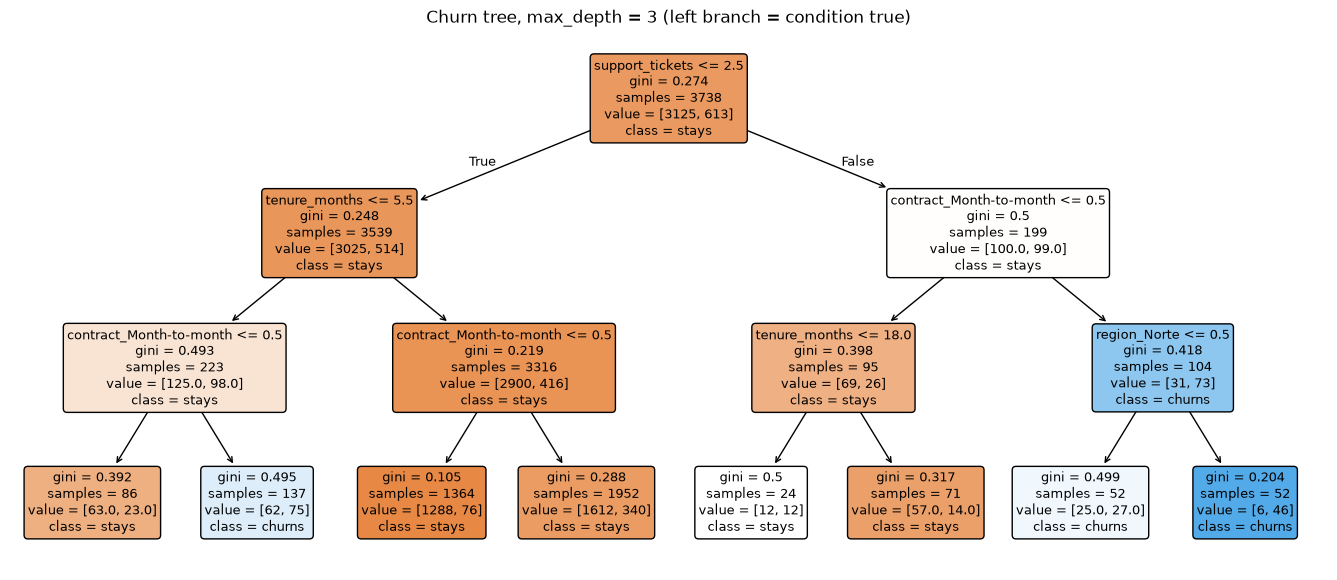

In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree3.fit(X_train, y_train)

plt.figure(figsize=(17, 7))
plot_tree(tree3, feature_names=list(X.columns), class_names=["stays", "churns"],
          filled=True, rounded=True, fontsize=9)
plt.title("Churn tree, max_depth = 3 (left branch = condition true)")
plt.show()

### Reading the tree as business rules

Each box shows its question, its Gini, how many training customers reached it (`samples`), how many stayed and churned (`value`), and the majority class. Colour shows the majority: orange boxes say "stays", blue boxes say "churns", and paler means more mixed.

The first question is `support_tickets <= 2.5`: tickets beat tenure by a hair, exactly as your Gini loop found. Follow a path from the top and you get a rule a manager can read without any code. Let's check the churn rules on the training customers:

In [10]:
train = X_train.assign(churned=y_train)
no_contract = train["contract_Month-to-month"] == 1

norte = train["region_Norte"] == 1
many_tickets = train["support_tickets"] >= 3

rules = {
    "3+ tickets, no contract, Norte": many_tickets & no_contract & norte,
    "3+ tickets, no contract, other regions": many_tickets & no_contract & ~norte,
    "new (< 6 months), 0-2 tickets, no contract": (train["tenure_months"] <= 5) & ~many_tickets & no_contract,
    "everyone": pd.Series(True, index=train.index),
}
for name, mask in rules.items():
    print(f"{name:<44} {mask.sum():>5,} customers   churn {train.loc[mask, 'churned'].mean():5.1%}")

3+ tickets, no contract, Norte                  52 customers   churn 88.5%
3+ tickets, no contract, other regions          52 customers   churn 51.9%
new (< 6 months), 0-2 tickets, no contract     137 customers   churn 54.7%
everyone                                     3,738 customers   churn 16.4%


In [11]:
auc_tree3 = roc_auc_score(y_test, tree3.predict_proba(X_test)[:, 1])
print(f"Tree, depth 3:       test AUC {auc_tree3:.3f}")
print(f"Logistic regression: test AUC {auc_logit:.3f}")

Tree, depth 3:       test AUC 0.674
Logistic regression: test AUC 0.723


**Business takeaway:** the rules are excellent for a slide (unhappy, uncommitted customers in the north are the hottest group), but as a scorer this tree is **worse** than the line. With 8 leaves it can only give 8 different probabilities, so it ranks customers coarsely. Should we just let it grow deeper? 

## <span class="hz-step-n">04</span> When trees memorize

Without `max_depth`, a tree keeps splitting until every leaf is pure, even if that leaf holds one customer. On the training data it is then **always right**. Look at what happens on customers it has never seen.

In [12]:
from sklearn.metrics import accuracy_score

full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)

print(f"Depth {full_tree.get_depth()}, {full_tree.get_n_leaves():,} leaves for {len(X_train):,} customers")
print(f"Accuracy  train {accuracy_score(y_train, full_tree.predict(X_train)):.3f}   test {accuracy_score(y_test, full_tree.predict(X_test)):.3f}")
print(f"AUC       train {roc_auc_score(y_train, full_tree.predict_proba(X_train)[:, 1]):.3f}   test {roc_auc_score(y_test, full_tree.predict_proba(X_test)[:, 1]):.3f}")

Depth 26, 583 leaves for 3,738 customers
Accuracy  train 1.000   test 0.747
AUC       train 1.000   test 0.563


A perfect score in training and a test accuracy **below** the "nobody churns" baseline of 83.6%: the tree has memorized the training customers, noise included. That is **overfitting**, the same problem you met with polynomials in session 3. The fix is to limit the depth. Which depth? Try them all.

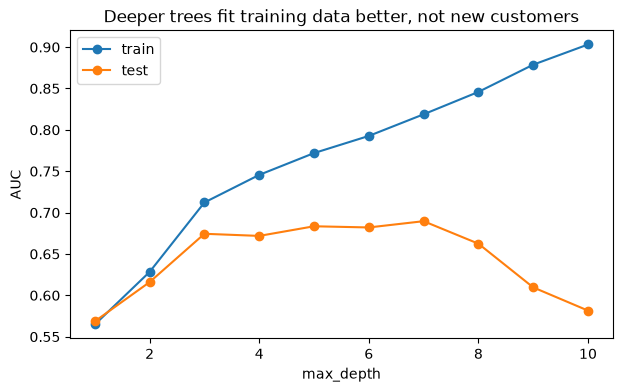

max_depth     1      2      3      4      5      6      7      8      9      10
train AUC  0.565  0.628  0.712  0.746  0.772  0.793  0.819  0.846  0.879  0.903
test AUC   0.569  0.616  0.674  0.672  0.683  0.682  0.690  0.662  0.610  0.582


In [13]:
rows = []
for depth in range(1, 11):
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    rows.append({
        "max_depth": depth,
        "train AUC": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
        "test AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
    })
depths = pd.DataFrame(rows).set_index("max_depth")

plt.figure(figsize=(7, 4))
plt.plot(depths.index, depths["train AUC"], marker="o", label="train")
plt.plot(depths.index, depths["test AUC"], marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("AUC")
plt.title("Deeper trees fit training data better, not new customers")
plt.legend()
plt.show()

print(depths.round(3).T.to_string())

In [14]:
best_depth = int(depths["test AUC"].idxmax())
print(f"Best depth: {best_depth}  (test AUC {depths.loc[best_depth, 'test AUC']:.3f})")

Best depth: 7  (test AUC 0.690)


The train curve keeps climbing; the test curve peaks and then falls. We pick the peak. (Strictly, you should choose the depth with cross-validation on the training set, as in session 4, and touch the test set only once at the end. With a small search like this one, the conclusion is the same.)

Even the best single tree stays below the logistic regression. One tree is **unstable**: change a few customers and the first question can change, and everything under it with it. The next idea fixes that.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Why does a tree with no <code>max_depth</code> get 100% accuracy on training data but much less on test data?", "options": ["It splits until each leaf is pure, so it learns the noise of individual training customers", "It uses too few features", "Gini impurity does not work on test data", "The test set is stratified and the training set is not"], "answer": 0, "why": "With no limit, the tree keeps asking questions until every leaf holds a single class, often a single customer. Those tiny leaves describe noise, not patterns, so they fail on new customers.", "code": false}</script>
</div>

## <span class="hz-step-n">05</span> A forest: many trees voting

A **random forest** grows hundreds of trees and lets them vote. Two kinds of randomness make the trees different from each other:

- **Bootstrap samples:** each tree trains on customers drawn at random *with replacement*, so some appear twice and about a third are left out.
- **Random features:** at each question, a tree may only look at a random handful of features, so not every tree starts with the obvious split.

Each tree makes its own mistakes; averaged, the mistakes cancel out and the pattern stays.

<div class="hz-widget" data-widget="forest-vote">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_5_Better_Models/">open this class on the course website</a> to use it.</p>
</div>

Two simplifications in the explainer: it draws the features once per tree (scikit-learn draws them again at every question), and it counts hard votes (scikit-learn averages each tree's probability). The idea is the same. Now on the real data, with 200 trees. `min_samples_leaf=5` stops any leaf from holding fewer than 5 customers, a gentler brake than `max_depth`.

In [15]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
forest.fit(X_train, y_train)
auc_forest = roc_auc_score(y_test, forest.predict_proba(X_test)[:, 1])

print(f"Random forest (200 trees): test AUC {auc_forest:.3f}")
print(f"Best single tree:          test AUC {depths['test AUC'].max():.3f}")
print(f"Logistic regression:       test AUC {auc_logit:.3f}")

Random forest (200 trees): test AUC 0.737
Best single tree:          test AUC 0.690
Logistic regression:       test AUC 0.723


Let's look inside the forest for one test customer, a close call. Each tree gives its own churn probability; the forest's answer is their average.

In [16]:
p_forest = pd.Series(forest.predict_proba(X_test)[:, 1], index=X_test.index)
who = (p_forest - 0.5).abs().idxmin()            # the customer closest to 50/50
customer = X_test.loc[[who]].to_numpy()

per_tree = np.array([t.predict_proba(customer)[0, 1] for t in forest.estimators_])
print(f"Customer {df.loc[who, 'customer_id']}: {df.loc[who, 'tenure_months']} months, "
      f"{df.loc[who, 'support_tickets']} tickets, {df.loc[who, 'contract']}, {df.loc[who, 'region']}")
print("First 10 trees:", np.round(per_tree[:10], 2))
print(f"Trees range from {per_tree.min():.2f} to {per_tree.max():.2f}; "
      f"{(per_tree >= 0.5).sum()} of {len(per_tree)} lean 'churn'")
print(f"Average of the 200 trees = forest probability: {per_tree.mean():.3f} (predict_proba says {p_forest[who]:.3f})")

Customer CM-10060: 5 months, 0 tickets, Month-to-month, Metropolitana
First 10 trees: [0.82 0.7  0.69 0.41 0.   0.8  1.   0.88 0.08 0.11]
Trees range from 0.00 to 1.00; 100 of 200 lean 'churn'
Average of the 200 trees = forest probability: 0.499 (predict_proba says 0.499)


## <span class="hz-step-n">06</span> Which features matter

The retention team will ask *"so what drives churn?"*. A forest answers with **feature importance**: how much each feature lowered the Gini, summed over every question in every tree.

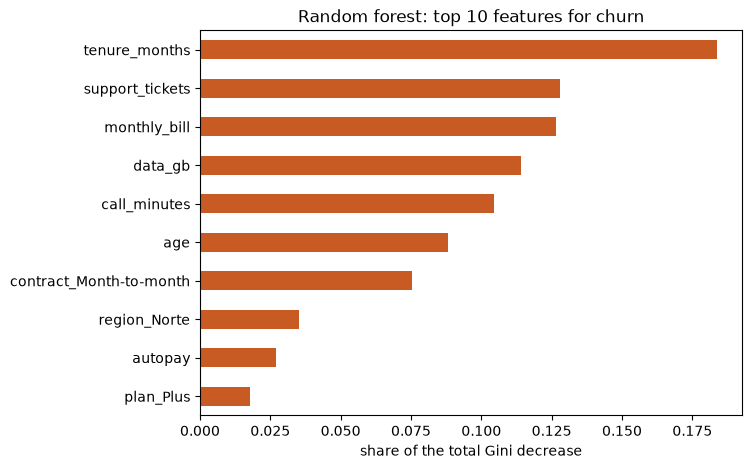

In [17]:
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 5))
importance.tail(10).plot.barh(color="#c85a24")
plt.xlabel("share of the total Gini decrease")
plt.title("Random forest: top 10 features for churn")
plt.show()

One caution before you put that chart on a slide: Gini importance favours numeric features with many possible thresholds (bill, data, minutes), even when they help little. A sturdier check is **permutation importance** on the test set: shuffle one column, and see how much the test AUC drops. If nothing drops, the model did not really need that feature.

In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(forest, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print("Drop in test AUC when the column is shuffled:")
for feature, drop in perm_imp.head(8).items():
    print(f"  {feature:<26} {drop:+.3f}")

Drop in test AUC when the column is shuffled:
  support_tickets            +0.051
  contract_Month-to-month    +0.048
  tenure_months              +0.032
  autopay                    +0.018
  region_Norte               +0.013
  plan_Unlimited             +0.005
  monthly_bill               +0.004
  plan_Plus                  +0.004


Importance says **how much** a feature matters, never **in which direction**. Check the direction with a simple table before you write a recommendation:

In [19]:
checks = {
    "new customer (< 6 months)": df["tenure_months"] < 6,
    "3+ support tickets": df["support_tickets"] >= 3,
    "no contract (month-to-month)": df["contract"] == "Month-to-month",
    "Norte with 2+ tickets": (df["region"] == "Norte") & (df["support_tickets"] >= 2),
    "autopay": df["autopay"] == 1,
}
for name, mask in checks.items():
    print(f"{name:<30} churn {df.loc[mask, 'churned'].mean():5.1%}  vs  {df.loc[~mask, 'churned'].mean():5.1%} for the rest")

new customer (< 6 months)      churn 44.4%  vs  14.5% for the rest
3+ support tickets             churn 49.8%  vs  14.5% for the rest
no contract (month-to-month)   churn 22.0%  vs   8.5% for the rest
Norte with 2+ tickets          churn 51.1%  vs  14.1% for the rest
autopay                        churn 12.1%  vs  19.9% for the rest


**Business takeaway, translated into actions:**

Permutation importance puts **support tickets**, **no contract** and **tenure** on top, and tickets and tenure also lead the Gini chart. Bill, data and minutes look important in the Gini chart, yet shuffling them barely moves the test AUC: that is the bias from the caution above, in action.

- **Support tickets** (above all in the Norte): the third ticket is an alarm. Action: escalate customers with 3+ tickets, and fix coverage complaints in the north first.
- **No contract:** customers who can leave any day, do. Action: offer month-to-month customers at risk a 12-month contract with a discount.
- **Tenure:** the first six months decide. Action: an onboarding call in months 1 to 3.

**Caution:** importance is not causation. Autopay customers churn less, but switching someone to autopay will not necessarily keep them; they may simply be more committed customers to begin with.

## <span class="hz-step-n">07</span> Comparing models fairly: ROC and AUC

A fair comparison uses **the same test customers** and a metric that does not depend on one threshold. The ROC curve shows, for every possible threshold, the share of churners you catch (true positive rate) against the share of loyal customers you bother (false positive rate). AUC is the area under it: 1.0 is perfect, 0.5 is a coin toss. The explainer uses toy buyers and non-buyers; the mechanism is the same for churners.

<div class="hz-widget" data-widget="roc">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_5_Better_Models/">open this class on the course website</a> to use it.</p>
</div>

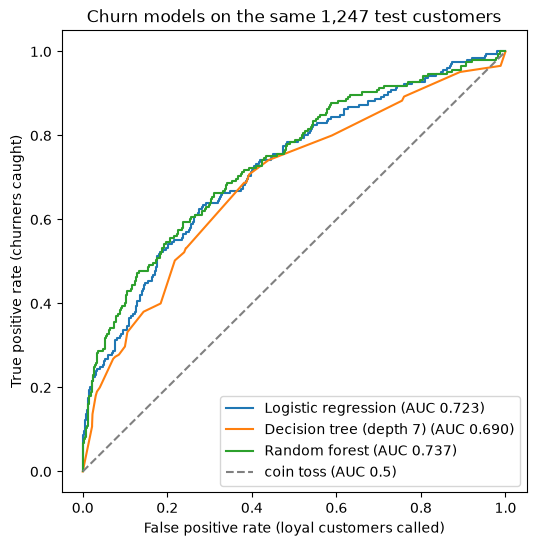

In [20]:
from sklearn.metrics import roc_curve

tree_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
models = {
    "Logistic regression": logit,
    f"Decision tree (depth {best_depth})": tree_best,
    "Random forest": forest,
}

plt.figure(figsize=(6, 6))
for name, model in models.items():
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="coin toss (AUC 0.5)")
plt.xlabel("False positive rate (loyal customers called)")
plt.ylabel("True positive rate (churners caught)")
plt.title(f"Churn models on the same {len(y_test):,} test customers")
plt.legend(loc="lower right")
plt.show()

The comparison table is what goes into your notebook and onto a slide. Next to AUC, add one number the business understands: if the team calls the **10% of customers the model ranks riskiest**, what share of all churners does it reach?

In [21]:
from sklearn.metrics import precision_score, recall_score

def caught_in_top(p, share=0.10):
    top = p >= np.quantile(p, 1 - share)
    return y_test[top].sum() / y_test.sum()

rows = []
for name, model in models.items():
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({
        "model": name,
        "test AUC": roc_auc_score(y_test, p),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "churners in top 10%": caught_in_top(p),
    })
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,test AUC,accuracy,precision,recall,churners in top 10%
model,,,,,
Logistic regression,0.723,0.852,0.750,0.146,0.278
Decision tree (depth 7),0.690,0.839,0.527,0.190,0.268
Random forest,0.737,0.845,0.667,0.117,0.322


The forest has the best AUC and reaches the most churners with the same number of calls. Notice how little accuracy, precision and recall at the default 0.5 threshold tell you here: with 16% churners, every model predicts "churn" rarely at 0.5. That is why you choose a threshold with the business (session 4) and compare models with AUC.

### A light tune-up (optional)

Could other settings do better? `GridSearchCV` tries each combination with cross-validation **on the training set only**. Keep searches small: here 6 combinations × 3 folds = 18 forests of 100 trees.

In [22]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=42),
    param_grid={"max_depth": [6, 10, None], "min_samples_leaf": [5, 20]},
    scoring="roc_auc",
    cv=3,
)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_)
print(f"Cross-validated AUC (train): {search.best_score_:.3f}")
print(f"Test AUC of the tuned forest: {roc_auc_score(y_test, search.predict_proba(X_test)[:, 1]):.3f}  (ours: {auc_forest:.3f})")

Best settings: {'max_depth': 6, 'min_samples_leaf': 20}
Cross-validated AUC (train): 0.768
Test AUC of the tuned forest: 0.739  (ours: 0.737)


Tuning moves the AUC in the third decimal. That is typical: **the choice of model family and good features matter far more than fine settings**. We keep our 200-tree forest.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A new churn model has a test AUC of 0.50. What does that mean?", "options": ["It catches half of the churners", "It ranks customers no better than a coin toss", "It is 50% accurate", "It needs a threshold of 0.5"], "answer": 1, "why": "AUC is the probability that a random churner gets a higher score than a random loyal customer. At 0.5 the scores carry no information: the ROC curve sits on the diagonal.", "code": false}</script>
</div>

## <span class="hz-step-n">08</span> For the commercial team: trees for the bill

Trees also predict numbers. A `RandomForestRegressor` averages the bills of the customers in each leaf instead of voting. Let's compare it with session 3's linear regression on `monthly_bill`, on session 3's own split.

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X_bill = X.drop(columns=["monthly_bill"])
y_bill = df["monthly_bill"]
# Session 3's split: 70/30, random_state=42
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_bill, y_bill, test_size=0.3, random_state=42)

bill_models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42),
}
rows = []
for name, model in bill_models.items():
    model.fit(Xb_train, yb_train)
    pred = model.predict(Xb_test)
    rows.append({"model": name, "test MAE (USD)": mean_absolute_error(yb_test, pred), "test R²": r2_score(yb_test, pred)})
pd.DataFrame(rows).set_index("model").round(3)

,test MAE (USD),test R²
model,,
Linear regression,2.870,0.924
Random forest,2.696,0.931


Here the line was already very good, because a bill really is a sum (plan price plus a price per GB plus roaming…). The forest still shaves a little off the error by catching that Unlimited plans charge almost nothing per extra GB, a kink the straight line averages away. But the linear model keeps one big advantage for the commercial team: its coefficients read as prices.

**Case A teams (TalentCo):** this is your second model. Same split, `RandomForestRegressor` next to your linear regression, MAE, RMSE and R² in one table, and a sentence on whether the gain is worth losing the coefficients.

## <span class="hz-step-n">09</span> From model to decision

A model is only useful when it changes what someone does on Monday. The retention team can call about **10% of customers a month**. Score the test customers, whom the model has never seen, and build the list.

In [24]:
scored = df.loc[X_test.index, ["customer_id", "tenure_months", "support_tickets", "contract", "region", "monthly_bill", "churned"]].copy()
scored["risk"] = p_forest

call_list = scored.sort_values("risk", ascending=False).head(int(len(scored) * 0.10))
print(f"Call list: {len(call_list)} of {len(scored)} test customers")
call_list.drop(columns="churned").head(10).round({"risk": 2})

Call list: 124 of 1247 test customers


,customer_id,tenure_months,support_tickets,contract,region,monthly_bill,risk
2549,CM-12403,26,4,Month-to-month,Norte,12.92,0.73
2426,CM-13952,6,3,Month-to-month,Norte,12.45,0.72
2033,CM-10058,10,3,Month-to-month,Norte,28.07,0.72
4596,CM-13537,32,3,Month-to-month,Norte,11.83,0.71
2003,CM-12652,29,3,Month-to-month,Norte,19.31,0.70
1170,CM-10001,58,3,Month-to-month,Norte,13.27,0.68
4452,CM-12581,67,3,Month-to-month,Norte,39.77,0.67
64,CM-11129,3,3,Month-to-month,Metropolitana,33.32,0.67
589,CM-10980,7,4,Month-to-month,Norte,32.60,0.66
846,CM-14077,9,3,Month-to-month,Norte,23.17,0.66


In [25]:
caught = call_list["churned"].sum()
random_hit = scored["churned"].mean() * len(call_list)
print(f"Real churners on the list: {caught} of {len(call_list)} ({caught / len(call_list):.0%} of calls)")
print(f"Calling {len(call_list)} customers at random would reach about {random_hit:.0f}")
print(f"That is {caught / random_hit:.1f}× more churners per call")

Real churners on the list: 66 of 124 (53% of calls)
Calling 124 customers at random would reach about 20
That is 3.2× more churners per call


Who is on the list? Compare its profile with the whole test set; this becomes the description of the target group on your slide.

In [26]:
def profile(group):
    return pd.Series({
        "no contract": (group["contract"] == "Month-to-month").mean(),
        "new (< 6 months)": (group["tenure_months"] < 6).mean(),
        "3+ tickets": (group["support_tickets"] >= 3).mean(),
        "Norte": (group["region"] == "Norte").mean(),
    })

traits = pd.DataFrame({"call list": profile(call_list), "all test customers": profile(scored)})
(traits * 100).round(0).astype(int).astype(str) + " %"

,call list,all test customers
no contract,88 %,59 %
new (< 6 months),41 %,6 %
3+ tickets,34 %,6 %
Norte,35 %,15 %


Finally, what is the list worth? Assume, as the retention team does, that a call with an offer keeps **3 in 10** of the churners it reaches. Scale the test set (a quarter of the base) up to all customers.

In [27]:
SAVE_RATE = 0.30                     # retention team's assumption: 3 in 10 called churners stay
scale_up = len(df) / len(scored)     # the test set is a quarter of the customer base

calls = len(call_list) * scale_up
saved_model = caught * SAVE_RATE * scale_up
saved_random = random_hit * SAVE_RATE * scale_up
print(f"Calls per month across the base: about {calls:.0f}")
print(f"Customers kept with the model's list: about {saved_model:.0f}")
print(f"Customers kept with a random list:    about {saved_random:.0f}")

Calls per month across the base: about 496
Customers kept with the model's list: about 79
Customers kept with a random list:    about 24


**Business takeaway:** same number of calls, more than three times the customers kept. That sentence, not the AUC, is what the retention team will remember. The assumption of 3 in 10 is the team's, not the model's: say so on the slide, and show what happens if it is 1 in 10.

## <span class="hz-step-n">10</span> Telling the story: the pyramid principle

You have 10 minutes with the retention director. A report tells the story in the order you **did** it: data, cleaning, charts, models, and the answer at minute nine. The **pyramid principle** turns it upside down:

1. **Key message first:** one sentence with the answer and the action.
2. **Three supporting arguments:** each one answers "why should I believe that?".
3. **Evidence under each argument:** one chart or number per point, nothing that does not support an argument.

If you are cut off at minute two, the director still has the answer. Build Cordillera's pyramid step by step, then flip it to report order to feel the difference.

<div class="hz-widget" data-widget="pyramid">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_5_Better_Models/">open this class on the course website</a> to use it.</p>
</div>

For a longer walkthrough with more examples, open the interactive class on [pyramid presentations](https://hizocar.github.io/usm-course-intensivo/classes/Pyramid_Presentations.html).

Here is Cordillera's pyramid written with the numbers this notebook computed, so the story and the evidence never drift apart:

In [28]:
pyramid = {
    "key message": f"Call the {len(call_list) / len(scored):.0%} of customers our forest flags each month: "
                   f"it reaches {caught / random_hit:.1f}x more future churners than calling at random.",
    "arguments": {
        "1. Churn is predictable": [
            f"ROC chart: forest AUC {auc_forest:.2f} vs logistic {auc_logit:.2f} vs coin 0.50",
            "Comparison table of the three models",
        ],
        "2. Three groups carry most of the risk": [
            "Feature importance: tickets, no contract, tenure",
            "Churn table: new customers, 3+ tickets, Norte with 2+ tickets",
        ],
        "3. A targeted list pays off": [
            f"Call list: {caught} churners in {len(call_list)} calls vs {random_hit:.0f} at random",
            f"About {saved_model:.0f} customers kept per month vs {saved_random:.0f} (if 3 in 10 are saved)",
        ],
    },
}
print("KEY MESSAGE:", pyramid["key message"])
for argument, evidence in pyramid["arguments"].items():
    print("\n" + argument)
    for item in evidence:
        print("   -", item)

KEY MESSAGE: Call the 10% of customers our forest flags each month: it reaches 3.2x more future churners than calling at random.

1. Churn is predictable
   - ROC chart: forest AUC 0.74 vs logistic 0.72 vs coin 0.50
   - Comparison table of the three models

2. Three groups carry most of the risk
   - Feature importance: tickets, no contract, tenure
   - Churn table: new customers, 3+ tickets, Norte with 2+ tickets

3. A targeted list pays off
   - Call list: 66 churners in 124 calls vs 20 at random
   - About 79 customers kept per month vs 24 (if 3 in 10 are saved)


A 10-minute plan for that pyramid:

| Minute | What you say | What is on screen |
|---|---|---|
| 0–1 | The key message and the action you ask for | One sentence, nothing else |
| 1–3 | Argument 1: churn is predictable | ROC curves and the comparison table |
| 3–6 | Argument 2: three groups carry the risk | Importance chart and the churn table |
| 6–8 | Argument 3: the list pays off | Call list profile and customers kept |
| 8–9 | Limitations: simulated save rate, one snapshot, importance ≠ causation | Short list |
| 9–10 | The key message again, and the next step | The same sentence as minute 0 |

Data cleaning and the code do not get a slide of their own: they live in the notebook, and you mention them only if someone asks.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "In a pyramid-structured presentation, what goes at the top, in the first minute?", "options": ["The data source and how it was cleaned", "The model comparison table", "The key message: the answer and the action you recommend", "The limitations of the analysis"], "answer": 2, "why": "The pyramid starts with the conclusion. Arguments and evidence come after it, to support it. Data and cleaning go in the notebook, not at the top of the story.", "code": false}</script>
</div>

## <span class="hz-step-n">11</span> Your project this week

This is the last content session, and it maps to the **[Final submission](https://hizocar.github.io/usm-course-intensivo/project/progress/#final-submission)**. Do for your case what we just did for Cordillera:

| We did with Cordillera | Case A · TalentCo (`Salary`) | Case B · FinTrust (`default`) |
|---|---|---|
| Forest and depth-limited tree on the same split as the logistic regression | `RandomForestRegressor` (or `DecisionTreeRegressor`) on the same split as your linear regression | `RandomForestClassifier` (or `DecisionTreeClassifier`) on the same stratified split as your logistic regression |
| Train vs test check over `max_depth` | Train vs test MAE, to catch overfitting | Train vs test AUC, to catch overfitting |
| Comparison table: AUC and churners in the top 10% | MAE, RMSE and R² for both models | Confusion matrix, precision, recall, F1 and AUC for both models |
| Importances, plus the direction from a simple table | Which variables drive salary, and whether there are gaps to fix | Which variables drive default, and how the risk team could use them |
| Call list and customers kept | What the people team should change, and for whom | Which applicants to review, and the cost of each error |
| Pyramid: key message, 3 arguments, evidence | Same structure, 10 minutes | Same structure, 10 minutes |

Your checklist (from [weekly progress](https://hizocar.github.io/usm-course-intensivo/project/progress/#final-submission)):

- [ ] Second model (decision tree or random forest) trained and evaluated on the **same split**.
- [ ] Model comparison table and a **justified** choice.
- [ ] Feature importance for the chosen model, explained for the business.
- [ ] Three recommendations and the limitations of the analysis.
- [ ] A 10-minute presentation with a pyramid structure.
- [ ] *Restart session and run all* works from top to bottom (see the [Colab guide](https://hizocar.github.io/usm-course-intensivo/colab/)); notebook submitted through the [mailbox](https://hizocar.github.io/usm-course-intensivo/project/mailbox/) and slides emailed.

**Due Tuesday, December 1, 23:59.** Present on December 2 or 4. Start the slides from your key message, not from your first chart.